In [67]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.append(str(root / "src" / "tabular"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [68]:
from collections import defaultdict
from gridworld import STATES, TERMINALS, ACTIONS, reset, sample_step, show

In [69]:
from common import value_iteration, greedy_policy, GridEnv

V = value_iteration()
pi = greedy_policy(V)

converged in 19 sweeps


In [70]:
def td_prediction(
    env: GridEnv, pi, n_episodes=5000, alpha=0.1, gamma=1.0, max_steps=100
):
    V_est = defaultdict(float)
    for _ in range(n_episodes):
        s = env.reset()
        for _ in range(max_steps):
            a = pi[s]
            ns, r, done = env.step(a)
            target = r + gamma * V_est[ns] * (not done)
            V_est[s] += alpha * (target - V_est[s])
            s = ns
            if done:
                break
    return V_est


env = GridEnv()
V_td = td_prediction(env, pi)
show(V=V_td)
show(V=V)

+0.86  +0.92  +0.95  +1.00 
+0.81    ##   +0.75  -1.00 
+0.75  +0.69  +0.00  +0.00 

+0.85  +0.91  +0.96  +1.00 
+0.80    ##   +0.70  -1.00 
+0.75  +0.70  +0.65  +0.43 



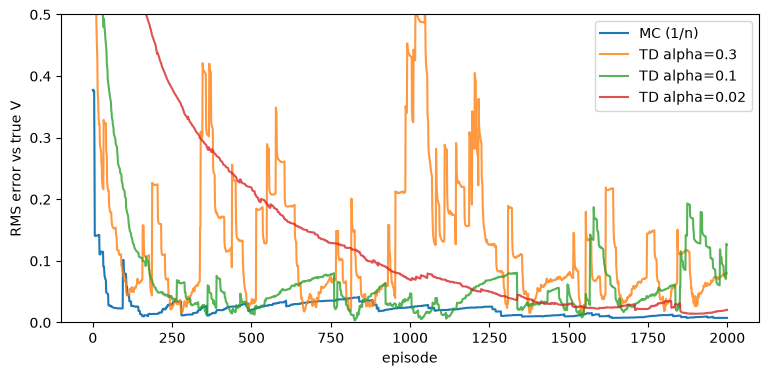

In [71]:
import numpy as np
import matplotlib.pyplot as plt

TRACKED = [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (1, 2), (2, 1)]  # states pi actually visits

def rms(V_est):
    return np.sqrt(np.mean([(V_est[s] - V[s]) ** 2 for s in TRACKED]))


def td_curve(env, pi, n_episodes=2000, alpha=0.1, gamma=1.0):
    V_est, errs = defaultdict(float), []
    for _ in range(n_episodes):
        s = env.reset()
        for _ in range(100):
            a = pi[s]
            ns, r, done = env.step(a)
            V_est[s] += alpha * (r + gamma * V_est[ns] * (not done) - V_est[s])
            s = ns
            if done:
                break
        errs.append(rms(V_est))
    return errs


def mc_curve(env, pi, n_episodes=2000, gamma=1.0):
    V_est, counts, errs = defaultdict(float), defaultdict(int), []
    for _ in range(n_episodes):
        s, ep = env.reset(), []
        for _ in range(100):
            a = pi[s]
            ns, r, done = env.step(a)
            ep.append((s, r))
            s = ns
            if done:
                break
        G, first = 0.0, {}
        for s_, r_ in reversed(ep):
            G = r_ + gamma * G
            first[s_] = G
        for s_, g in first.items():
            counts[s_] += 1
            V_est[s_] += (g - V_est[s_]) / counts[s_]
        errs.append(rms(V_est))
    return errs


plt.figure(figsize=(9, 4))
plt.plot(mc_curve(env, pi), label="MC (1/n)")
for a in [0.3, 0.1, 0.02]:
    plt.plot(td_curve(env, pi, alpha=a), label=f"TD alpha={a}", alpha=0.8)
plt.xlabel("episode"); plt.ylabel("RMS error vs true V"); plt.ylim(0, 0.5)
plt.legend(); plt.show()


In [72]:
import random

def epsilon_greedy(Q, s, n_actions, eps=0.1):
    if random.random() < eps:
        return random.randrange(n_actions)
    return max(range(n_actions), key=lambda a: Q[(s, a)])

# The name is literally the tuple it uses: State, Action, Reward, State, Action.
def sarsa(env, n_episodes=5000, alpha=0.1, gamma=1.0, eps=0.1, max_steps=100):
    returns = []
    Q = defaultdict(float)
    for _ in range(n_episodes):
        total = 0.0
        s = env.reset()
        a = epsilon_greedy(Q, s, env.n_actions, eps)      # action chosen BEFORE the loop
        for _ in range(max_steps):
            ns, r, done = env.step(a)
            total += r
            na = epsilon_greedy(Q, ns, env.n_actions, eps)  # and the next one, now
            target = r + gamma * Q[(ns, na)] * (not done)
            Q[(s, a)] += alpha * (target - Q[(s, a)])
            s, a = ns, na
            if done:
                break
        returns.append(total)
    return Q, returns

def q_learning(env, n_episodes=5000, alpha=0.1, gamma=1.0, eps=0.1, max_steps=100):
    returns = []
    Q = defaultdict(float)
    for _ in range(n_episodes):
        total = 0.0
        s = env.reset()
        for _ in range(max_steps):
            a = epsilon_greedy(Q, s, env.n_actions, eps)
            ns, r, done = env.step(a)
            total += r
            target = r + gamma * max(
                Q[(ns, a2)] for a2 in range(env.n_actions)
            ) * (not done)
            Q[(s, a)] += alpha * (target - Q[(s, a)])
            s = ns
            if done:
                break
        returns.append(total)
    return Q, returns


In [73]:
def policy_from_Q(Q, n_actions=4):
    return {s: max(range(n_actions), key=lambda a: Q[(s, a)])
            for s in STATES if s not in TERMINALS}

env = GridEnv(explore=True)      # exploring starts, so the corners get learned
for name, fn in [("sarsa", sarsa), ("q_learning", q_learning)]:
    Q_, _ = fn(env, n_episodes=20_000)
    print(name)
    show(pi=policy_from_Q(Q_))
    show(V=defaultdict(float, {s: max(Q_[(s, a)] for a in range(4))
                               for s in STATES if s not in TERMINALS}))
print('optimal')
show(pi=pi)
show(V=V)

sarsa
  >      >      >    +1.00 
  ^      ##     ^    -1.00 
  ^      <      <      <   

+0.86  +0.90  +0.98  +1.00 
+0.78    ##   +0.62  -1.00 
+0.71  +0.63  +0.56  +0.41 

q_learning
  >      >      >    +1.00 
  ^      ##     <    -1.00 
  ^      <      <      <   

+0.87  +0.88  +0.94  +1.00 
+0.83    ##   +0.63  -1.00 
+0.76  +0.70  +0.65  +0.57 

optimal
  >      >      >    +1.00 
  ^      ##     ^    -1.00 
  ^      <      <      <   

+0.85  +0.91  +0.96  +1.00 
+0.80    ##   +0.70  -1.00 
+0.75  +0.70  +0.65  +0.43 



In [74]:
from common import GymEnv
def show_cliff(Q):
    for r in range(4):
        row = []
        for c in range(12):
            s = r * 12 + c
            if s == 47:
                row.append("G")
            elif r == 3 and 1 <= c <= 10:
                row.append("C")
            else:
                row.append("^>v<"[max(range(4), key=lambda a: Q[(s, a)])])
        print(" ".join(row))
    print()


In [75]:
cliff = GymEnv("CliffWalking-v1")

Q_s, _ = sarsa(cliff, n_episodes=500, alpha=0.5, eps=0.1, max_steps=200)
Q_q, _ = q_learning(cliff, n_episodes=500, alpha=0.5, eps=0.1, max_steps=200)

print("SARSA");      show_cliff(Q_s)
print("Q-LEARNING"); show_cliff(Q_q)


SARSA
> > > > > > > > > > > v
^ > > ^ < ^ ^ ^ ^ ^ > v
^ ^ ^ ^ ^ ^ < ^ ^ ^ > v
^ C C C C C C C C C C G

Q-LEARNING
> > > v > > > > > > > v
> > > > > > > > v > > v
> > > > > > > > > > > v
^ C C C C C C C C C C G



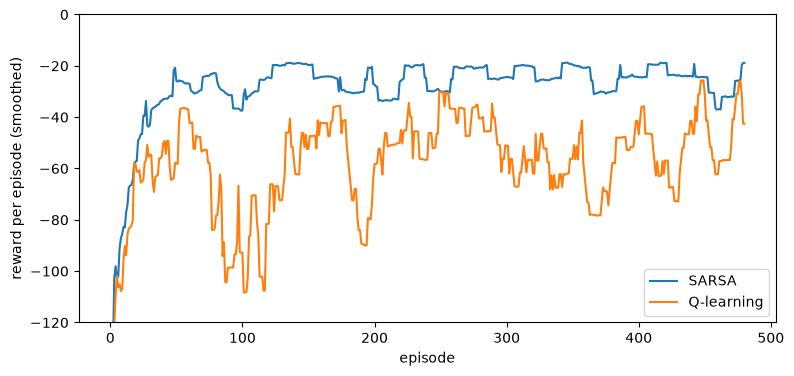

greedy (eps=0) — sarsa: -17.0  q-learning: -13.0


In [76]:
def smooth(xs, k=20):
    return np.convolve(xs, np.ones(k) / k, mode="valid")

cliff = GymEnv("CliffWalking-v1")
Q_s, ret_s = sarsa(cliff, n_episodes=500, alpha=0.5, eps=0.1, max_steps=200)
Q_q, ret_q = q_learning(cliff, n_episodes=500, alpha=0.5, eps=0.1, max_steps=200)

plt.figure(figsize=(9, 4))
plt.plot(smooth(ret_s), label="SARSA")
plt.plot(smooth(ret_q), label="Q-learning")
plt.xlabel("episode"); plt.ylabel("reward per episode (smoothed)")
plt.ylim(-120, 0); plt.legend(); plt.show()


def greedy_return(Q, env, max_steps=200):
    s, total = env.reset(), 0.0
    for _ in range(max_steps):
        s, r, done = env.step(max(range(4), key=lambda a: Q[(s, a)]))
        total += r
        if done:
            break
    return total

print("greedy (eps=0) — sarsa:", greedy_return(Q_s, cliff),
      " q-learning:", greedy_return(Q_q, cliff))
